# Engineering Mathematics Computer Assignment
- **Name**: Sadegh Samadi
- **Student ID**: 810102588
****
If you have any questions, contact the TAs:
- **Babak Hosseini Mohtasham**:
    - *Email*: babak.hosseini.m@ut.ac.ir
    - *Telegram*: @babakstar
- **Sina**
    - *Email*: msina.parvizi@ut.ac.ir
    - *Telegram*: @Mosipamo

# Imports

In [68]:
import numpy as np
import matplotlib.pyplot as plt
import math
import cv2
from sklearn.metrics import mean_squared_error

# Part 1: Discrete Fourier Series in 1D

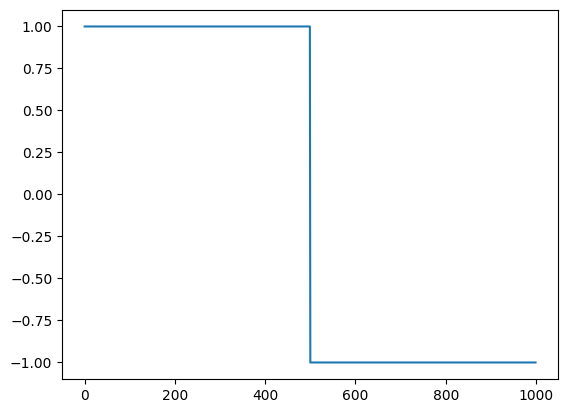

In [69]:
N = 1000
T = 2 * 500
x = np.arange(N)
y = np.where(x < T / 2, 1, -1)
plt.plot(x,y)

In [70]:
def discrete_fourier_series(f, N, n):
    a_n = (2.0 / N) * np.sum(f * np.cos(2 * np.pi * n * x / N))
    b_n = (2.0 / N) * np.sum(f * np.sin(2 * np.pi * n * x / N))
    return a_n, b_n

In [71]:
def reconstruct_function(num_term):
    x_recon = x
    y_recon = []

    a_0, _ = discrete_fourier_series(y, N, 0)
    for t in x_recon:
        f_t = a_0 / 2
        for n in range(1, num_term + 1):
            a_n, b_n = discrete_fourier_series(y, N, n)
            f_t += a_n * np.cos(2 * np.pi * n * t / T) + b_n * np.sin(2 * np.pi * n * t / T)
        y_recon.append(f_t)
    return y_recon

a_0=0.000000
a_1=0.004000
b_1=1.273235
a_2=-0.000000
b_2=-0.000000
a_3=0.004000
b_3=0.424401
a_4=0.000000
b_4=0.000000
a_5=0.004000
b_5=0.254627


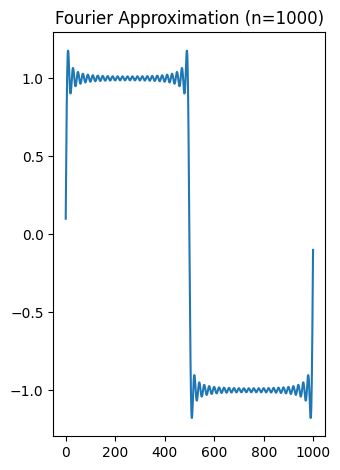

In [72]:
y_recon = reconstruct_function(50)
a_0, _ = discrete_fourier_series(y, N, 0)
print(f"a_0={a_0:.6f}")
for n in range(1, 6):
    a_n, b_n = discrete_fourier_series(y, N, n)
    print(f"a_{n}={a_n:.6f}")
    print(f"b_{n}={b_n:.6f}")
plt.subplot(1, 2, 2)
x_plot = x
plt.plot(x_plot, y_recon)
plt.title(f"Fourier Approximation (n={N})")
plt.tight_layout()
plt.show()


### Calculating first coefficients in theory
$$
f(t)=
\begin{cases}
+1, & 0 < t < \tfrac{T}{2},\\[6pt]
-1, & \tfrac{T}{2} < t < T,
\end{cases}
$$

$$
a_0 = \frac{1}{T}\int_{0}^{T} f(t)\,dt = 0,
$$

$$
a_n = \frac{2}{T}\int_{0}^{T} f(t)\cos\!\Bigl(\tfrac{2\pi n}{T}t\Bigr)\,dt = 0
,
$$

$$
b_n = \frac{2}{T}\int_{0}^{T} f(t)\sin\!\Bigl(\tfrac{2\pi n}{T}t\Bigr)\,dt
   = \begin{cases}
      \dfrac{4}{\pi n}, & n\text{ odd},\\[6pt]
      0,                 & n\text{ even}.
     \end{cases}
$$

$$
b_1 = \frac{4}{\pi}\approx1.2732.
$$

$$
b_3 = \frac{4}{3\pi}\approx0.4244.
$$

$$
b_5 = \frac{4}{5\pi}\approx0.2546.
$$
*All of the remaining coefficients are zero, and the theoretical values agree perfectly with the computed results.*


Loss (n=2): 0.189428
Loss (n=5): 0.066936
Loss (n=50): 0.008038


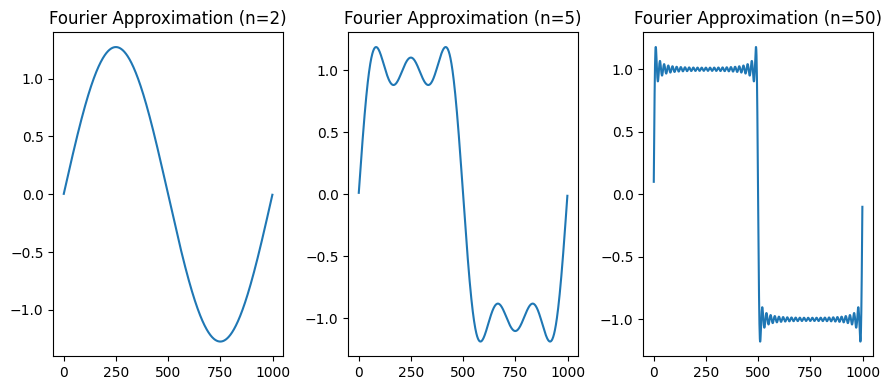

In [73]:
num_terms = [2, 5, 50]
resolution = 100
plt.figure(figsize=(3*len(num_terms), 4))

for i, num in enumerate(num_terms):
    plt.subplot(1, len(num_terms), i+1)
    y_recon = reconstruct_function(num)
    x_plot = x
    plt.plot(x_plot, y_recon)
    plt.title(f"Fourier Approximation (n={num})")
    plt.tight_layout()
    loss = mean_squared_error(y, y_recon)
    print(f"Loss (n={num}): {loss:.6f}")
    # Print losses

plt.show()

Clearly, as we include more terms, the approximation becomes more accurate and the loss decreases.

# Part 2: Discrete Fourier Series in 2D

## Grayscale image

In [74]:
def load_grayscale_image(path, width, height):
    image = cv2.imread(path, cv2.IMREAD_GRAYSCALE) / 255.0
    image = cv2.resize(image, dsize=(width, height), interpolation=cv2.INTER_CUBIC)
    return image

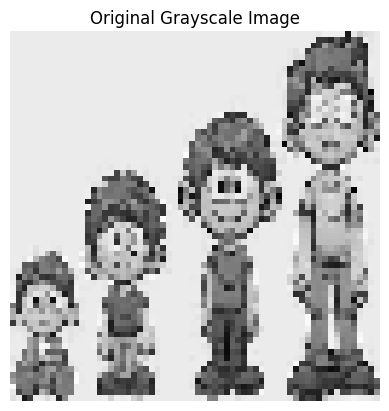

In [75]:
PATH = "download.jpg"
image = load_grayscale_image(PATH, 64, 64)

plt.imshow(image, cmap='gray')
plt.title('Original Grayscale Image')
plt.axis('off')

plt.show()

In [76]:
def dft2d(image):
    M, N = image.shape
    output = np.zeros((M, N), dtype = complex)
    for k in range(M):
        for l in range(N):
            term = 0+0j
            for m in range(M): 
                for n in range(N):
                    angle = -2j * np.pi * (k * m / M + l * n / N)
                    term += image[m, n] * np.exp(angle)
            output[k, l] = term
    return output

def idft2d(image):
    M, N = image.shape
    output = np.zeros((M, N), dtype = complex)
    for m in range(M):
        for n in range(N):
            term = 0+0j
            for k in range(M):
                for l in range(N):
                    angle = 2j * np.pi * (k * m / M + l * n / N)
                    term += image[k, l] * np.exp(angle)
            output[m, n] = term / (M * N)
    return output.real

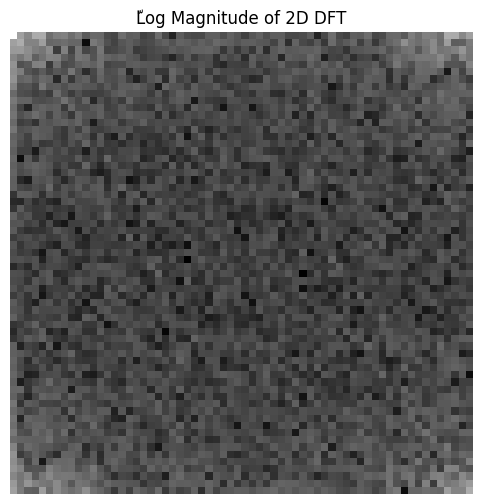

In [77]:
F = dft2d(image)

plt.figure(figsize=(15, 6))
log_magnitude_dft = np.log(1 + np.abs(F))

plt.imshow(log_magnitude_dft, cmap='gray')
plt.title('ّLog Magnitude of 2D DFT')
plt.axis('off')
plt.show()

In [78]:
def compress_image(F, fraction):
    M, N = F.shape
    compressed_F = np.zeros((M, N), dtype = complex)
    total = M * N
    k = int(np.floor(fraction * total))
    flat = F.ravel()
    idx = np.argsort(np.abs(flat))[::-1]
    mask_flat = np.zeros_like(flat, dtype = bool)
    mask_flat[idx[:k]] = True
    compressed_F = (flat * mask_flat).reshape(M, N)
    return compressed_F

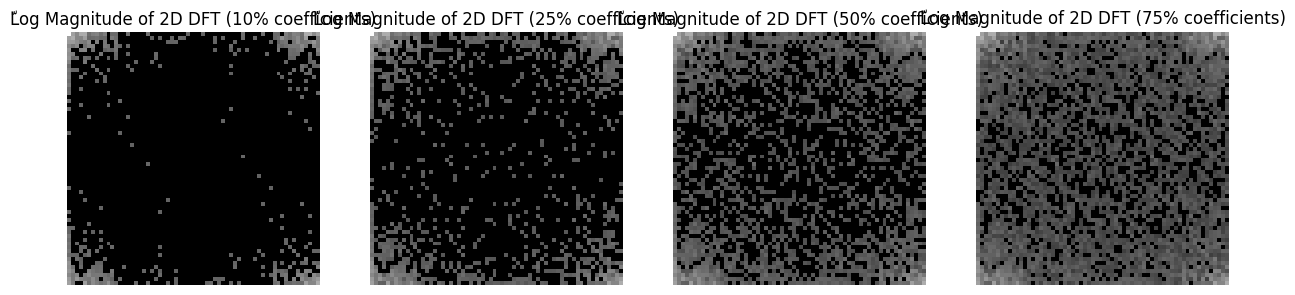

In [79]:
fractions = [0.1, 0.25, 0.5, 0.75]
plt.figure(figsize=(15, 6))

for i, frac in enumerate(fractions):
    plt.subplot(1, len(fractions), i + 1)
    
    compressed_F = compress_image(F, frac)
    log_magnitude_dft = np.log(1 + np.abs(compressed_F))
    
    plt.imshow(log_magnitude_dft, cmap='gray')
    plt.title(f'ّLog Magnitude of 2D DFT ({frac *100:.0f}% coefficients)')
    plt.axis('off')
    
plt.show()

*In the 1D Fourier series, the largest coefficients always occur at the lowest frequencies and then steadily decrease as the frequency increases. so retaining the first few harmonics gives a very close approximation of the original signal. In contrast, when we look at the 2D DFT magnitude image, the highest‐magnitude values appear in the corners, and the values decrease as we move toward the center.*

Loss (25% coefficients):0.013422161541992009
Loss (50% coefficients):0.004708628148839456
Loss (75% coefficients):0.0010226680632606385
Loss (100% coefficients):1.0968995053005786e-05


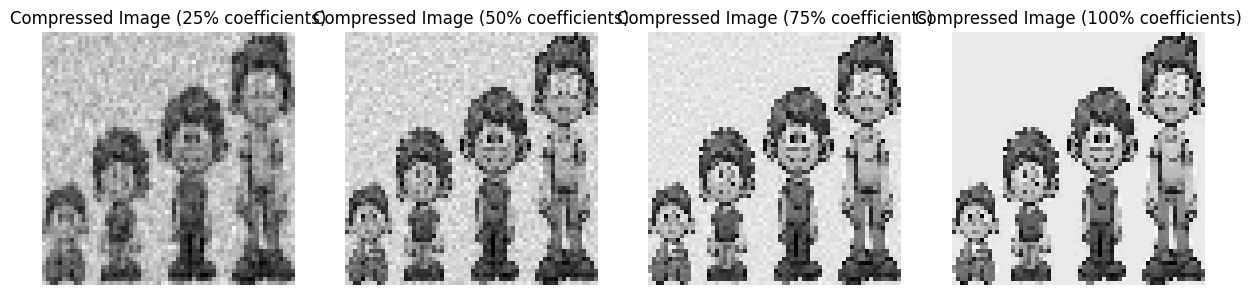

In [80]:
fractions = [0.25, 0.5, 0.75, 1]
plt.figure(figsize=(15, 6))

for i, frac in enumerate(fractions):
    compressed_F = compress_image(F, frac)
    reconstructed_image = np.abs(idft2d(compressed_F))

    plt.subplot(1, len(fractions), i + 1)
    plt.imshow(reconstructed_image, cmap='gray')
    plt.title(f'Compressed Image ({frac *100:.0f}% coefficients)')
    plt.axis('off')
    loss = mean_squared_error(image, reconstructed_image)
    print(f"Loss ({frac *100:.0f}% coefficients):{loss}")
    
plt.show()

## Colored image

In [81]:
def load_image(path, width, height):
    image = cv2.imread(path, cv2.IMREAD_COLOR)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, dsize=(width, height),
                       interpolation=cv2.INTER_CUBIC) / 255.0
    return image

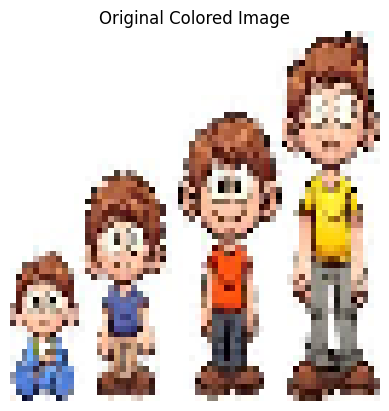

In [82]:
image = load_image(PATH, 64, 64)
F_rgb = np.zeros_like(image, dtype=complex)

plt.imshow(image, cmap='gray')
plt.title('Original Colored Image')
plt.axis('off')

plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.09891206190795487..8.116927484142982].


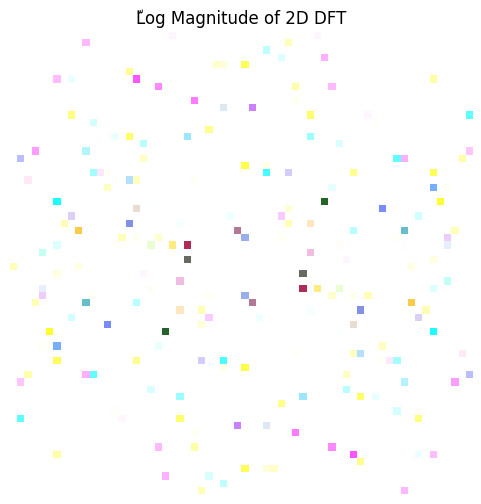

In [83]:
# Similar to gray scale
def dft2d_color(image):
    M, N, C = image.shape
    F = np.zeros((M, N, C), dtype = complex)
    for c in range(C):
        F[:,:,c] = dft2d(image[:,:,c])
    return F

def idft2d_color(image):
    M, N, C = image.shape
    F = np.zeros((M, N, C))
    for c in range(C):
        F[:,:,c] = idft2d(image[:,:,c])
    return F
def compress_image_color(image, fraction):
    M, N, C = image.shape
    F = np.zeros_like(image)
    for c in range(C):
        F[:,:,c] = compress_image(image[:,:,c], fraction)
    return F

F = dft2d_color(image)

plt.figure(figsize=(15, 6))
log_magnitude_dft = np.log(1 + np.abs(F))

plt.imshow(log_magnitude_dft)
plt.title('ّLog Magnitude of 2D DFT')
plt.axis('off')
plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..8.116927484142982].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..8.116927484142982].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..8.116927484142982].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..8.116927484142982].


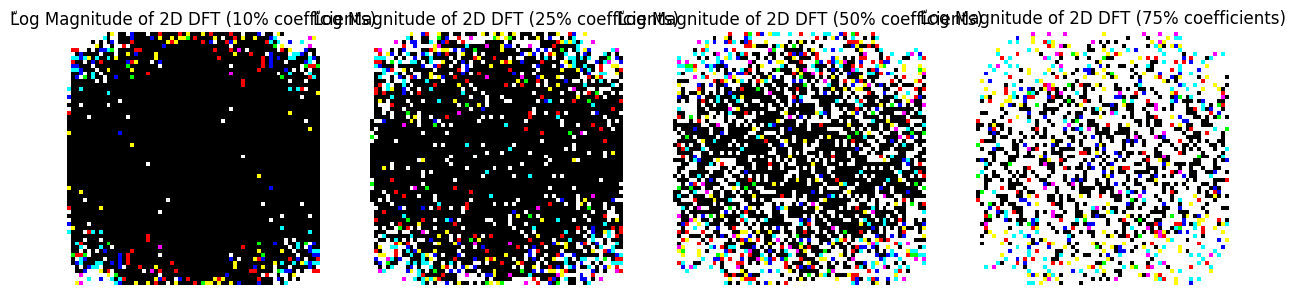

In [84]:
fractions = [0.1, 0.25, 0.5, 0.75]
plt.figure(figsize=(15, 6))

for i, frac in enumerate(fractions):
    plt.subplot(1, len(fractions), i + 1)
    
    compressed_F = compress_image_color(F, frac)
    log_magnitude_dft = np.log(1 + np.abs(compressed_F))
    
    plt.imshow(log_magnitude_dft, cmap='gray')
    plt.title(f'ّLog Magnitude of 2D DFT ({frac *100:.0f}% coefficients)')
    plt.axis('off')
    
plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0010025265887280057..1.3159244562958248].


Loss (25% coefficients):0.012857524960603842


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.00015317923554736268..1.1936601320737856].


Loss (50% coefficients):0.0044435876531319805


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0014928459417953358..1.1127721381167222].


Loss (75% coefficients):0.0009578276701758443


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [6.938893903907228e-17..1.0000000000000522].


Loss (100% coefficients):1.1870205151971559e-28


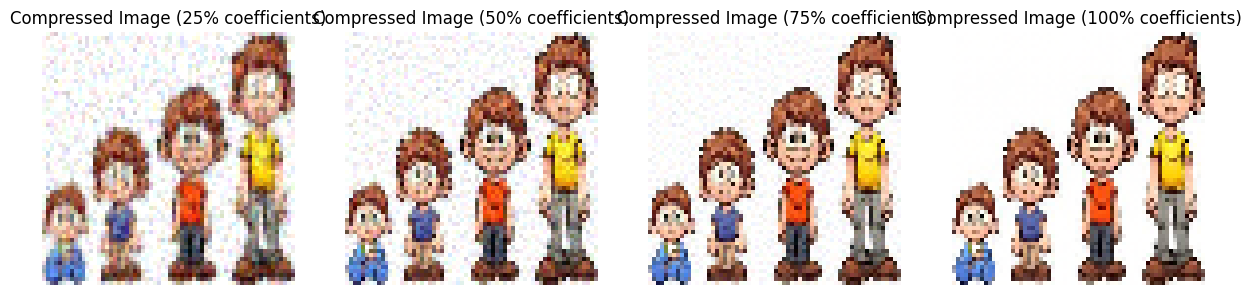

In [85]:
fractions = [0.25, 0.5, 0.75, 1]
plt.figure(figsize=(15, 6))

for i, frac in enumerate(fractions):
    compressed_F = compress_image_color(F, frac)
    reconstructed_image = np.abs(idft2d_color(compressed_F))

    plt.subplot(1, len(fractions), i + 1)
    plt.imshow(reconstructed_image)
    plt.title(f'Compressed Image ({frac *100:.0f}% coefficients)')
    plt.axis('off')
    y = image.reshape(-1, 3)
    y_recon = reconstructed_image.reshape(-1, 3)
    loss = mean_squared_error(y, y_recon)
    print(f"Loss ({frac *100:.0f}% coefficients):{loss}")
    
plt.show()